# Evaluación Sumativa 3. Modelamiento predictivo integrado
## Framingham Heart Study: riesgo de enfermedad coronaria a 10 años

MCDI501 · Grupo 3 · Integrantes: Felipe Díaz Toro, Pablo Ríos Passteni, Guillermo Subiabre Chacón, Ninoska Yévenes Hernández


## Introducción

La enfermedad coronaria (CHD) es una de las principales causas de muerte en el mundo. El estudio de Framingham siguió a 4.238 personas y registró si presentaron CHD en los 10 años siguientes (`TenYearCHD`). Solo el 15,2 % de los casos la desarrolló, por lo que la clase de interés es minoritaria.

Esta Sumativa 3 integra lo hecho en S1 (exploración y valores faltantes), S2 (validación y remuestreo) y F2 (regresión logística) en un modelo predictivo completo. El trabajo avanza en cuatro frentes:

1. **Datos faltantes.** Imputamos la glucosa (9,16 % de faltantes) mediante regresión lineal múltiple y la comparamos con eliminar los casos y con imputar la mediana.
2. **Tres modelos logísticos** con distintos criterios de selección: variables validadas en S2 (edad y presión sistólica), *stepwise* por AIC y un modelo reducido. Se comparan con odds ratios por desviación estándar y curvas ROC.
3. **Bootstrap** de los coeficientes del mejor modelo, para contrastar sus intervalos de confianza con los tradicionales.
4. **Ponderación de clases** (peso ≈ 3,3 para los casos) para mejorar el recall, que en F2 fue de solo 4,7 %.

### Qué haremos antes de cargar los datos
- **Configuración:** importar las librerías y fijar la semilla (42), la variable objetivo y la paleta de colores.
- **Verificación de integridad:** comprobar que el archivo es el original (huella SHA-256 y forma 4.238 × 16).
- **Primera mirada:** confirmar la prevalencia de CHD y la cantidad de faltantes en la glucosa.

## 0. Configuración y datos

In [1]:
import hashlib
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (confusion_matrix, accuracy_score, precision_score,
                             recall_score, f1_score, roc_auc_score, roc_curve)

# Raíz del repo: la carpeta que contiene requirements.txt y redaccion/
ROOT = Path.cwd()
while not ((ROOT / "requirements.txt").exists() and (ROOT / "redaccion").exists()):
    if ROOT == ROOT.parent:
        raise FileNotFoundError("No se encontró la raíz del repositorio")
    ROOT = ROOT.parent

CSV = ROOT / "data" / "raw" / "framingham.csv"
SHA_ESPERADO = "40921748dbdf6587045b9822414199a1ae3349358b63b975ab2208aa3cccc45b"
FORMA_ESPERADA = (4238, 16)
SEED = 42
TARGET = "TenYearCHD"

# Paleta del grupo
NAVY, RED, GREY, BG, OCHRE = "#0d2741", "#ae0000", "#8c8578", "#f6f1ea", "#c0852f"
plt.rcParams.update({"figure.facecolor": BG, "axes.facecolor": BG,
                     "axes.edgecolor": GREY, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10})

# Verificación de integridad del dataset
sha = hashlib.sha256(CSV.read_bytes()).hexdigest()
df = pd.read_csv(CSV)
assert sha == SHA_ESPERADO, "El CSV no coincide con el original"
assert df.shape == FORMA_ESPERADA, f"Forma inesperada: {df.shape}"
print("Dataset verificado:", df.shape, "| SHA-256 OK")
print(f"Prevalencia de {TARGET}: {df[TARGET].mean():.2%}")
print(f"Glucosa faltante: {df['glucose'].isna().sum()} ({df['glucose'].isna().mean():.2%})")

Dataset verificado: (4238, 16) | SHA-256 OK
Prevalencia de TenYearCHD: 15.20%
Glucosa faltante: 388 (9.16%)


## 1. Manejo inteligente de datos faltantes

Hasta ahora, en S1, F2 y S2, los datos faltantes se trataron con soluciones rápidas: eliminar filas o rellenar con la mediana. Eran decisiones razonables para avanzar, pero tienen un costo que todavía no medimos. Eliminar filas reduce la muestra y puede sesgarla; la mediana, en cambio, rellena a todos con el mismo valor, aplana la variable y debilita las relaciones que esa variable tiene con las demás.

En Framingham, 582 de las 4.238 personas (13,7 %) tienen al menos un dato faltante. El caso más pesado es la **glucosa**, con 388 registros faltantes (9,16 %), casi diez veces más que cualquier otra variable. Como la glucosa es un predictor clínicamente relevante del riesgo coronario, la forma en que la tratemos puede cambiar las conclusiones del modelo. Por eso concentramos la comparación en ella.

El plan de esta sección tiene tres pasos:
1. **Entender por qué faltan.** No da igual que los datos falten al azar o que falten por una razón ligada a otras variables: de eso depende qué estrategias son defendibles.
2. **Imputar con una regresión lineal múltiple**, que rellena cada valor faltante con una predicción basada en variables relacionadas con la glucosa, en lugar de un valor único para todos.
3. **Comparar tres estrategias** (eliminar, mediana y regresión) para ver con evidencia cuánto cambia la muestra, la distribución de la glucosa y sus relaciones con el resto.

### 1.1 ¿Por qué faltan estos datos?

Antes de rellenar nada conviene preguntarse por qué faltan. Hay tres posibilidades. Si faltan **por puro azar** (MCAR), cualquier método sirve y solo se pierde precisión. Si la falta **depende de otras variables que sí observamos** (MAR), como que en personas sin diabetes se mida menos la glucosa, entonces eliminar filas sesga la muestra, pero imputar usando esas variables es válido. Si la falta depende **del propio valor que no vemos** (MNAR), ningún método estándar lo corrige por completo.

En S1 ya comparamos la falta de glucosa con la enfermedad coronaria, sin encontrar relación significativa (χ² = 1,58; p = 0,21). Eso no prueba nada, porque no descarta que la falta dependa de otras variables. Aquí hacemos la comparación completa: contrastamos, para cada variable sin faltantes, a quienes tienen la glucosa registrada con quienes no, y luego usamos todas juntas en una regresión que intenta predecir quién tendrá la glucosa faltante.

Un punto de honestidad metodológica: estos tests solo pueden **rechazar** MCAR. Ninguno puede demostrar MAR, porque MNAR depende de lo que no observamos. Lo que haremos es adoptar MAR como supuesto de trabajo, explicitarlo y justificar por qué es razonable.

In [2]:
from scipy import stats

faltantes = (df.isna().sum().to_frame("n_faltantes")
               .assign(pct=lambda d: (d.n_faltantes / len(df) * 100).round(2))
               .query("n_faltantes > 0")
               .sort_values("n_faltantes", ascending=False))
display(faltantes)
print("Filas con algún faltante:", df.isna().any(axis=1).sum())

,n_faltantes,pct
glucose,388,9.16
education,105,2.48
BPMeds,53,1.25
totChol,50,1.18
cigsPerDay,29,0.68
BMI,19,0.45
heartRate,1,0.02


Filas con algún faltante: 582


In [3]:
df["glu_falta"] = df["glucose"].isna().astype(int)
completas = [c for c in df.columns
             if df[c].notna().all() and c not in ("glu_falta", TARGET)]
binarias = [c for c in completas if df[c].nunique() == 2]
continuas = [c for c in completas if c not in binarias]

filas = []
for c in continuas:                       # t de Welch
    a, b = df.loc[df.glu_falta == 1, c], df.loc[df.glu_falta == 0, c]
    filas.append((c, f"{a.mean():.2f}", f"{b.mean():.2f}", stats.ttest_ind(a, b, equal_var=False).pvalue))
for c in binarias:                        # chi-cuadrado
    tab = pd.crosstab(df[c], df.glu_falta)
    filas.append((c, f"{df.loc[df.glu_falta == 1, c].mean():.1%}",
                  f"{df.loc[df.glu_falta == 0, c].mean():.1%}", stats.chi2_contingency(tab)[1]))

comp = pd.DataFrame(filas, columns=["variable", "glucosa faltante", "glucosa observada", "p"])
comp["p"] = comp["p"].round(4)
display(comp.sort_values("p"))

,variable,glucosa faltante,glucosa observada,p
3,male,29.6%,44.3%,0.0000
7,diabetes,1.0%,2.7%,0.0652
0,age,49.00,49.64,0.1480
4,currentSmoker,52.8%,49.1%,0.1731
1,sysBP,131.39,132.45,0.3456
6,prevalentHyp,28.9%,31.3%,0.3581
2,diaBP,82.54,82.93,0.5243
5,prevalentStroke,0.3%,0.6%,0.5832


In [4]:
X = sm.add_constant(df[completas].astype(float))
m_falta = sm.Logit(df["glu_falta"], X).fit(disp=0)
lr_p = m_falta.llr_pvalue
print(f"Pseudo R² = {m_falta.prsquared:.3f} | test de razón de verosimilitud p = {lr_p:.4g}")
print(m_falta.summary2().tables[1].round(4)[["Coef.", "P>|z|"]])

# Solo diagnóstico: la tasa de CHD según faltante (el target NO se usa para imputar)
print(df.groupby("glu_falta")[TARGET].mean().round(4))

Pseudo R² = 0.017 | test de razón de verosimilitud p = 3.345e-07
                  Coef.   P>|z|
const           -2.1207  0.0002
male            -0.6991  0.0000
age             -0.0036  0.6192
currentSmoker    0.2547  0.0235
prevalentStroke -0.7984  0.4366
prevalentHyp    -0.0381  0.8208
diabetes        -0.8834  0.0867
sysBP           -0.0030  0.5273
diaBP            0.0068  0.3825
glu_falta
0    0.1543
1    0.1289
Name: TenYearCHD, dtype: float64


### Qué vemos

De las siete variables con faltantes, la glucosa es la más afectada (388 registros, 9,16 %), muy por encima de educación (2,48 %), medicación antihipertensiva (1,25 %) y el resto (menos del 1,2 %). En total, 582 personas tienen al menos un dato faltante.

Al comparar a quienes tienen la glucosa registrada con quienes no, **la única diferencia clara es el sexo**: entre los registros sin glucosa hay un 29,6 % de hombres, contra un 44,3 % entre los que sí la tienen (p < 0,0001). Es decir, la glucosa falta con más frecuencia en mujeres. La regresión logística confirma este patrón: a igualdad del resto de las variables, ser hombre reduce a la mitad aproximadamente la probabilidad de que falte (OR ≈ 0,50). El tabaquismo actual muestra un efecto menor (OR ≈ 1,29; p = 0,024), que preferimos no sobreinterpretar porque surge de varias comparaciones simultáneas. La diabetes presenta una diferencia en la dirección esperada (1,0 % vs 2,7 %), pero no alcanza significancia (p = 0,065) y se apoya en muy pocos casos. Edad, presión arterial, hipertensión y antecedente de ACV no se diferencian.

Estas diferencias son pequeñas en conjunto: las variables observadas explican muy poco de quién tiene la glucosa faltante (pseudo R² = 0,017). Tampoco hay relación clara con el desenlace: la tasa de enfermedad coronaria es de 12,9 % entre los faltantes y 15,4 % entre los observados, coherente con lo hallado en S1 (p = 0,21).

**Supuesto de trabajo.** La evidencia permite **rechazar MCAR**, porque la falta de glucosa depende del sexo. Adoptamos **MAR** como supuesto: la probabilidad de que falte la glucosa depende de variables que sí observamos, principalmente el sexo. Esto no puede demostrarse con los datos, ya que un mecanismo MNAR (la glucosa falta por su propio valor) es indistinguible desde lo observado. Lo que sí implica es una decisión práctica: **el sexo debe incluirse como predictor en la imputación por regresión**, y eliminar casos sería menos defendible, pues dejaría la muestra con menos mujeres de las que tenía.

### 1.2 Imputación mediante regresión lineal múltiple

Imputar con la mediana le da a las 388 personas el mismo valor de glucosa, sin importar si son hombres o mujeres, jóvenes o mayores, diabéticos o no. La imputación por regresión intenta algo mejor: **predecir la glucosa de cada persona a partir de otras variables que sí conocemos**, de modo que el valor rellenado refleje su perfil. Para que el método sea honesto con la evaluación posterior, seguimos tres reglas. Primero, **partimos los datos antes de imputar** (70 % entrenamiento, 30 % prueba, estratificado por `TenYearCHD`), y el modelo de imputación se ajusta solo con el entrenamiento; así el conjunto de prueba no influye en nada de lo que se aprende. Segundo, los predictores se eligen por criterio y no por intuición: entre las variables **sin faltantes**, tomamos las que más se correlacionan con la glucosa en S1, dando prioridad a las que S2 validó como estables (edad y presión sistólica), y sumamos el sexo, que en la sección anterior resultó ser lo que explica la falta. Tercero, **la variable objetivo no se usa jamás** como predictor ni se imputa: haría que el modelo supiera la respuesta que después debe predecir.

In [5]:
# Partición 70/30 estratificada, ANTES de imputar (misma semilla que F2)
train, test = train_test_split(df.drop(columns="glu_falta"), test_size=0.30,
                               stratify=df[TARGET], random_state=SEED)
print(f"train = {len(train)} | test = {len(test)}")
print(f"Prevalencia CHD: train {train[TARGET].mean():.2%} | test {test[TARGET].mean():.2%}")

# Candidatos a predictor: variables SIN faltantes (se excluye el target)
candidatos = [c for c in df.columns
              if df[c].notna().all() and c not in (TARGET, "glu_falta")]

# Correlación con la glucosa, solo casos completos del train
tr_glu = train.dropna(subset=["glucose"])
print(f"Casos completos de glucosa en train: {len(tr_glu)}")
corr = pd.DataFrame({
    "pearson": tr_glu[candidatos].corrwith(tr_glu["glucose"]),
    "spearman": tr_glu[candidatos].corrwith(tr_glu["glucose"], method="spearman"),
}).round(3)
corr["|pearson|"] = corr["pearson"].abs()
display(corr.sort_values("|pearson|", ascending=False).drop(columns="|pearson|"))


train = 2966 | test = 1272
Prevalencia CHD: train 15.21% | test 15.17%
Casos completos de glucosa en train: 2680


,pearson,spearman
diabetes,0.635,0.237
sysBP,0.135,0.109
age,0.112,0.108
prevalentHyp,0.077,0.067
currentSmoker,-0.063,-0.081
diaBP,0.054,0.034
prevalentStroke,0.035,0.022
male,0.013,-0.016


**Partición y elección de predictores.** La partición estratificada dejó 2.966 personas en entrenamiento y 1.272 en prueba, con la misma prevalencia de enfermedad coronaria en ambas (15,21 % y 15,17 %). De las 2.966 de entrenamiento, 2.680 tienen la glucosa registrada y son las que usamos para ajustar el modelo de imputación.

Entre las variables sin faltantes, **la diabetes es, por lejos, la que más se asocia con la glucosa** (r = 0,635), seguida de la presión sistólica (0,135) y la edad (0,112); el resto queda bajo 0,08. La distancia entre la correlación de Pearson de la diabetes (0,635) y la de Spearman (0,237) indica que esa relación se sostiene en pocos valores muy altos, de personas diabéticas, y no en un aumento gradual de la glucosa. Esto lo tendremos presente al revisar los residuos.

Los predictores elegidos son cinco: **diabetes, presión sistólica y edad** (por correlación, y las dos últimas por estar validadas en S2), **sexo** (porque explica la falta de glucosa según 1.1, aunque casi no se correlaciona con ella) y **tabaquismo actual** (efecto débil sobre la falta). La presión diastólica y la hipertensión quedan fuera porque son redundantes con la sistólica, y el antecedente de ACV por su correlación casi nula.

n = 2680 | R² = 0.408 | R² ajustado = 0.407 | RMSE = 18.37 mg/dL


,Coef.,Std.Err.,P>|t|
const,68.897,2.706,0.000
diabetes,89.302,2.143,0.000
sysBP,0.063,0.018,0.000
age,0.057,0.046,0.212
male,-0.178,0.732,0.808
currentSmoker,-1.018,0.746,0.172


RMSE validación cruzada -> regresión: 18.59 | mediana: 24.19
Asimetría de los residuos: 2.14


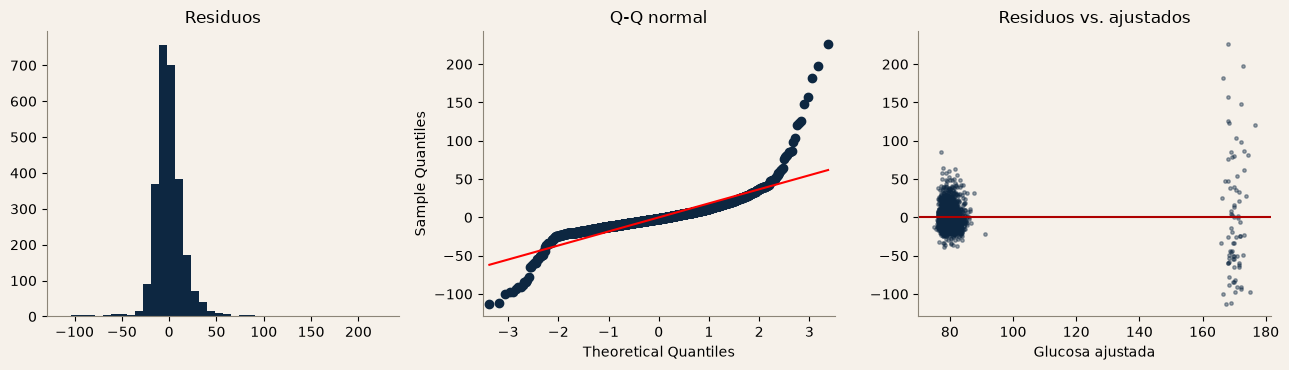

In [6]:
from sklearn.model_selection import KFold

pred = ["diabetes", "sysBP", "age", "male", "currentSmoker"]
y = tr_glu["glucose"]
X = sm.add_constant(tr_glu[pred].astype(float))
ols = sm.OLS(y, X).fit()

print(f"n = {int(ols.nobs)} | R² = {ols.rsquared:.3f} | R² ajustado = {ols.rsquared_adj:.3f} "
      f"| RMSE = {np.sqrt(ols.mse_resid):.2f} mg/dL")
display(ols.summary2().tables[1].round(3)[["Coef.", "Std.Err.", "P>|t|"]])

# Desempeño fuera de muestra (validación cruzada 5 pliegues) vs imputar la mediana
err_reg, err_med = [], []
for tr_i, va_i in KFold(5, shuffle=True, random_state=SEED).split(tr_glu):
    m = LinearRegression().fit(tr_glu.iloc[tr_i][pred], y.iloc[tr_i])
    err_reg.append(y.iloc[va_i] - m.predict(tr_glu.iloc[va_i][pred]))
    err_med.append(y.iloc[va_i] - y.iloc[tr_i].median())
rmse = lambda e: np.sqrt(np.mean(np.concatenate(e) ** 2))
print(f"RMSE validación cruzada -> regresión: {rmse(err_reg):.2f} | mediana: {rmse(err_med):.2f}")

# Supuestos: residuos
res, ajust = ols.resid, ols.fittedvalues
print(f"Asimetría de los residuos: {stats.skew(res):.2f}")
fig, ax = plt.subplots(1, 3, figsize=(13, 3.8))
ax[0].hist(res, bins=40, color=NAVY); ax[0].set_title("Residuos")
sm.qqplot(res, line="s", ax=ax[1], markerfacecolor=NAVY, markeredgecolor=NAVY)
ax[1].set_title("Q-Q normal")
ax[2].scatter(ajust, res, s=6, alpha=.4, color=NAVY); ax[2].axhline(0, color=RED)
ax[2].set_title("Residuos vs. ajustados"); ax[2].set_xlabel("Glucosa ajustada")
plt.tight_layout(); plt.show()

Con el modelo ajustado, imputamos la glucosa en el entrenamiento y en la prueba **usando siempre el modelo del entrenamiento**. Generamos dos versiones. En la primera, cada valor faltante recibe la **predicción** de la regresión. En la segunda, a esa predicción se le suma un **residuo tomado al azar** de los residuos observados, de modo que los valores imputados conserven la dispersión real de la glucosa y no se amontonen en torno a un único valor. A ambas las acotamos entre el mínimo y el máximo observados en el entrenamiento, para no generar glucosas imposibles. También dejamos lista la imputación por mediana, que usaremos como comparación en la sección 1.3.

In [7]:
rng = np.random.default_rng(SEED)
modelo_imp = LinearRegression().fit(tr_glu[pred], y)      # mismo ajuste que el OLS
residuos = (y - modelo_imp.predict(tr_glu[pred])).to_numpy()
g_min, g_max, g_mediana = y.min(), y.max(), y.median()

def imputar(d):
    d = d.copy()
    falta = d["glucose"].isna()
    p = modelo_imp.predict(d.loc[falta, pred])
    d["glu_mediana"] = d["glucose"].fillna(g_mediana)
    d["glu_reg"] = d["glucose"]
    d.loc[falta, "glu_reg"] = np.clip(p, g_min, g_max)
    d["glu_reg_ruido"] = d["glucose"]
    d.loc[falta, "glu_reg_ruido"] = np.clip(p + rng.choice(residuos, falta.sum()), g_min, g_max)
    d["glu_imputada"] = falta
    return d

train_i, test_i = imputar(train), imputar(test)

print(f"Valores imputados: train {train_i.glu_imputada.sum()} ({train_i.glu_imputada.mean():.2%}) | "
      f"test {test_i.glu_imputada.sum()} ({test_i.glu_imputada.mean():.2%})")
print(f"Total: {train_i.glu_imputada.sum() + test_i.glu_imputada.sum()} (esperado: 388)")

# ¿Cómo quedan los valores imputados frente a los observados? (train)
obs = train_i.loc[~train_i.glu_imputada, "glucose"]
resumen = pd.DataFrame({
    "observada": obs.describe(),
    "mediana": train_i.loc[train_i.glu_imputada, "glu_mediana"].describe(),
    "regresión": train_i.loc[train_i.glu_imputada, "glu_reg"].describe(),
    "regresión + ruido": train_i.loc[train_i.glu_imputada, "glu_reg_ruido"].describe(),
}).round(1)
display(resumen)

Valores imputados: train 286 (9.64%) | test 102 (8.02%)


Total: 388 (esperado: 388)


,observada,mediana,regresión,regresión + ruido
count,2680.0,286.0,286.0,286.0
mean,82.1,78.0,80.3,80.3
std,23.9,0.0,9.3,22.9
min,40.0,78.0,76.2,40.0
25%,71.0,78.0,78.1,69.4
50%,78.0,78.0,79.2,77.1
75%,87.0,78.0,80.5,85.0
max,394.0,78.0,172.1,275.9


### Qué vemos

El modelo de imputación se ajustó con las 2.680 personas del entrenamiento que tienen glucosa registrada y explica el 41 % de su variación (R² = 0,408; error típico de 18,4 mg/dL). En validación cruzada, su error (18,6 mg/dL) es un 23 % menor que el de imputar la mediana (24,2 mg/dL), sin señales de sobreajuste. Sin embargo, esa mejora proviene casi por completo de la **diabetes**, que suma unos 89 mg/dL a la glucosa predicha; la presión sistólica aporta un efecto significativo pero mínimo (0,6 mg/dL por cada 10 mmHg), y la edad, el sexo y el tabaquismo no son significativos. En la práctica, el modelo distingue a las personas con diabetes del resto.

Los supuestos del modelo lineal se cumplen solo en parte: los residuos son asimétricos (asimetría = 2,14), tienen colas pesadas y su varianza es mucho mayor entre los diabéticos que entre los demás. Esto resta confiabilidad a los valores p de la tabla de coeficientes, pero no invalida el uso del modelo para imputar, ya que lo que necesitamos de él son predicciones promedio.

Se imputaron 388 valores de glucosa: 286 en el entrenamiento (9,64 %) y 102 en la prueba (8,02 %). Como casi todas esas personas no tienen diabetes, la regresión les asigna valores cercanos a 80 mg/dL (media 80,3; desviación estándar 9,3), de modo que la glucosa imputada es **mucho menos variable que la real** (desviación estándar 23,9). Es una mejora frente a la mediana, que repite un mismo valor (78,0) en todos, pero sigue siendo una compresión. La versión con ruido residual recupera la dispersión (22,9), aunque la exagera en las colas (máximo 275,9), porque sortea residuos que incluyen los de las personas diabéticas. Ambas versiones se comparan en la sección siguiente.

### 1.3 ¿Importa cómo tratemos la glucosa faltante?

Ya tenemos cuatro formas de resolver el problema: **eliminar** a las personas sin glucosa, imputar la **mediana**, imputar con la **regresión** e imputar con la regresión más **ruido residual**. Antes de elegir una para el resto del trabajo, las miramos con tres preguntas:

1. **¿Cuánta muestra y qué tipo de muestra queda?** Eliminar filas no solo achica el dataset: como la glucosa falta más en mujeres, también puede cambiar su composición.
2. **¿Qué le pasa a la distribución de la glucosa?** Una buena imputación no debería inventar una glucosa más uniforme (ni más extrema) que la real.
3. **¿Se conservan las relaciones que vimos en S1?** Lo que más importa es que la glucosa siga relacionada con la diabetes, la presión y la edad como antes. Una imputación que las diluye debilita los modelos que vienen después.

Todo se calcula sobre el conjunto de entrenamiento. La referencia para las relaciones es la glucosa realmente observada.

,n,% del train,% hombres,edad media,prevalencia CHD
Eliminación,2680,90.4%,44.4%,49.8,15.52%
Mediana,2966,100.0%,43.3%,49.7,15.21%
Regresión,2966,100.0%,43.3%,49.7,15.21%
Regresión + ruido,2966,100.0%,43.3%,49.7,15.21%


,media,desv. est.,asimetría,mediana,P95,máx
Eliminación,82.07,23.85,5.74,78.00,109.00,394.0
Mediana,81.68,22.71,6.07,78.00,107.00,394.0
Regresión,81.90,22.86,5.97,78.21,107.75,394.0
Regresión + ruido,81.90,23.77,5.65,78.00,108.00,394.0


,diabetes,sysBP,age,TenYearCHD
Eliminación,0.635,0.135,0.112,0.120
Mediana,0.623,0.129,0.108,0.116
Regresión,0.642,0.137,0.110,0.121
Regresión + ruido,0.615,0.135,0.098,0.114


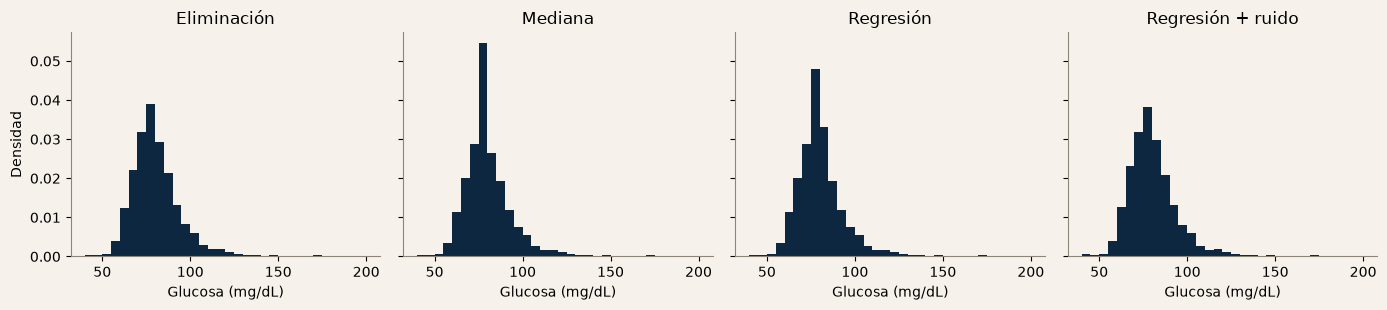

In [8]:
tr = train_i
elim = tr[~tr.glu_imputada]            # eliminación: solo casos con glucosa observada
estrategias = {
    "Eliminación":       (elim, elim["glucose"]),
    "Mediana":           (tr, tr["glu_mediana"]),
    "Regresión":         (tr, tr["glu_reg"]),
    "Regresión + ruido": (tr, tr["glu_reg_ruido"]),
}

# 1) Tamaño y composición de la muestra
t1 = pd.DataFrame({
    nom: {"n": len(d), "% del train": f"{len(d)/len(tr):.1%}",
          "% hombres": f"{d['male'].mean():.1%}",
          "edad media": f"{d['age'].mean():.1f}",
          "prevalencia CHD": f"{d[TARGET].mean():.2%}"}
    for nom, (d, g) in estrategias.items()}).T
display(t1)

# 2) Distribución de la glucosa
t2 = pd.DataFrame({
    nom: {"media": g.mean(), "desv. est.": g.std(), "asimetría": stats.skew(g),
          "mediana": g.median(), "P95": g.quantile(.95), "máx": g.max()}
    for nom, (d, g) in estrategias.items()}).T.round(2)
display(t2)

# 3) Relaciones con la glucosa (correlación de Pearson)
vars_rel = ["diabetes", "sysBP", "age", TARGET]
t3 = pd.DataFrame({
    nom: {v: d[v].corr(g) for v in vars_rel}
    for nom, (d, g) in estrategias.items()}).T.round(3)
display(t3)

# Gráfico: distribución de la glucosa por estrategia
fig, ax = plt.subplots(1, 4, figsize=(14, 3.2), sharey=True)
for a, (nom, (d, g)) in zip(ax, estrategias.items()):
    a.hist(g, bins=np.arange(40, 205, 5), color=NAVY, density=True)
    a.set_title(nom); a.set_xlabel("Glucosa (mg/dL)")
ax[0].set_ylabel("Densidad")
plt.tight_layout(); plt.show()

### Qué vemos

Como solo el 9,6 % de las glucosas del entrenamiento fue imputado, las diferencias entre estrategias son pequeñas, pero hay un patrón claro.

- **Muestra:** eliminar deja 2.680 de 2.966 personas (90,4 %) y cambia levemente su composición (hombres de 43,3 % a 44,4 %), coherente con que la glucosa falta más en mujeres. Las imputaciones conservan a todos.
- **Distribución:** la mediana crea un pico artificial en 78 mg/dL (desviación estándar 22,71 frente a 23,85 real). La regresión mejora algo (22,86), y la regresión con ruido es la más fiel (23,77).
- **Relaciones:** la regresión conserva las correlaciones de S1 (diferencias menores a 0,01), la mediana las debilita levemente y la versión con ruido es la que más las diluye. La correlación con la enfermedad coronaria, que no entró en la imputación, se mantiene (0,121 frente a 0,120).

**Estrategia elegida:** imputación por regresión determinista. Conserva toda la muestra, preserva las relaciones de S1 y no depende del azar. La eliminación queda como referencia, y la mediana y la regresión con ruido como análisis de sensibilidad en la sección 3.

## 2. Clasificación mediante regresión logística (30 pts + 30 pts de bootstrap)
### 2.1 Preparación de datos informada por S1
Partimos de `train_i`/`test_i` (1.2), con la glucosa imputada por regresión. Los faltantes menores de las demás variables (ninguno por encima del 2,5 %, no son el foco de esta sección) se resuelven con la mediana del entrenamiento. Se acota la cola de la glucosa observada al percentil 99 del entrenamiento, como en S2 y F2, y se estandarizan todos los predictores. `education` se excluye: es ordinal con 105 faltantes propios y una asociación débil con el desenlace (verificado abajo), y mezclar su imputación/codificación no aporta a los tres modelos de 2.2.

In [9]:
# Correlación de education con el desenlace, para justificar su exclusión
educ = df[["education", TARGET]].dropna()
print(f"Correlación education-TenYearCHD (S1): {educ['education'].corr(educ[TARGET]):.3f} (n={len(educ)})")

candidatos_s3 = ["male", "age", "currentSmoker", "cigsPerDay", "BPMeds", "prevalentStroke",
                 "prevalentHyp", "diabetes", "totChol", "sysBP", "diaBP", "BMI", "heartRate", "glucose"]

# Dataset final: la glucosa es la imputada por regresión (1.2); el resto son faltantes menores
train_f, test_f = train_i.copy(), test_i.copy()
train_f["glucose"] = train_f["glu_reg"]
test_f["glucose"] = test_f["glu_reg"]

menores = ["cigsPerDay", "BPMeds", "totChol", "BMI", "heartRate"]
medianas_menores = train_f[menores].median()
for d in (train_f, test_f):
    d[menores] = d[menores].fillna(medianas_menores)
print("Faltantes restantes en los predictores (train, test):",
      int(train_f[candidatos_s3].isna().sum().sum()), int(test_f[candidatos_s3].isna().sum().sum()))

# Outliers: tope de glucosa al P99 de train, calculado solo con los casos observados (como en S2/F2)
tope_glu = train_f.loc[~train_f.glu_imputada, "glucose"].quantile(0.99)
for d in (train_f, test_f):
    d["glucose"] = d["glucose"].clip(upper=tope_glu)
print(f"Tope de glucosa (P99 de train, casos observados): {tope_glu:.1f} mg/dL")

# Estandarización con media/desviación del train
X_train = train_f[candidatos_s3].astype(float)
X_test = test_f[candidatos_s3].astype(float)
scaler_s3 = StandardScaler().fit(X_train)
X_train_sc = pd.DataFrame(scaler_s3.transform(X_train), columns=candidatos_s3, index=X_train.index)
X_test_sc = pd.DataFrame(scaler_s3.transform(X_test), columns=candidatos_s3, index=X_test.index)
y_train, y_test = train_f[TARGET], test_f[TARGET]

X_train_sc.describe().round(2).loc[["mean", "std"]]

Correlación education-TenYearCHD (S1): -0.054 (n=4133)
Faltantes restantes en los predictores (train, test): 0 0
Tope de glucosa (P99 de train, casos observados): 187.1 mg/dL


,male,age,currentSmoker,cigsPerDay,BPMeds,prevalentStroke,prevalentHyp,diabetes,totChol,sysBP,diaBP,BMI,heartRate,glucose
mean,-0.0,-0.0,-0.0,-0.0,0.0,-0.0,0.0,0.0,-0.0,0.0,-0.0,0.0,-0.0,-0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


### 2.2 Tres modelos logísticos
Tres criterios de selección distintos sobre los mismos datos (2.1): (1) las cinco variables de F2, ya validadas con evidencia doble S1+S2; (2) selección hacia adelante por AIC sobre los 14 candidatos; (3) comparación directa por AIC/BIC entre los candidatos ya construidos (el 1, el 2 y el modelo completo de 14 variables), quedándonos con el que minimiza BIC, el criterio más conservador con el tamaño muestral.

In [10]:
# Modelo 1: las cinco variables de F2 (age, sysBP, male, cigsPerDay, glucose), validadas con S1+S2
vars_m1 = ["age", "sysBP", "male", "cigsPerDay", "glucose"]

def ajustar(cols, nombre):
    m = sm.Logit(y_train, sm.add_constant(X_train_sc[cols])).fit(disp=0)
    print(f"{nombre}: {len(cols)} variables | AIC = {m.aic:.1f} | BIC = {m.bic:.1f} | pseudo R² = {m.prsquared:.3f}")
    return m

m1 = ajustar(vars_m1, "Modelo 1 (S1/S2, dominio)")
print(m1.summary2().tables[1].round(4)[["Coef.", "P>|z|"]])

Modelo 1 (S1/S2, dominio): 5 variables | AIC = 2242.4 | BIC = 2278.4 | pseudo R² = 0.118
             Coef.   P>|z|
const      -1.9933  0.0000
age         0.6080  0.0000
sysBP       0.4005  0.0000
male        0.2011  0.0005
cigsPerDay  0.2951  0.0000
glucose     0.1665  0.0003


In [11]:
# Modelo 2: seleccion hacia adelante por AIC sobre los 14 candidatos de 2.1
def forward_aic(X, y, candidatos):
    seleccion, restante = [], list(candidatos)
    aic_actual = sm.Logit(y, sm.add_constant(pd.Series(1.0, index=X.index, name="const"))).fit(disp=0).aic
    trayectoria = []
    while restante:
        aics = {c: sm.Logit(y, sm.add_constant(X[seleccion + [c]])).fit(disp=0).aic for c in restante}
        mejor_var = min(aics, key=aics.get)
        if aics[mejor_var] < aic_actual:
            aic_actual = aics[mejor_var]
            seleccion.append(mejor_var)
            restante.remove(mejor_var)
            trayectoria.append((mejor_var, round(aic_actual, 1)))
        else:
            break
    return seleccion, trayectoria

vars_m2, trayectoria_m2 = forward_aic(X_train_sc, y_train, candidatos_s3)
print("Orden de incorporación (variable, AIC acumulado):")
for paso, (v, a) in enumerate(trayectoria_m2, 1):
    print(f"  {paso}. {v:16s} AIC = {a}")

m2 = ajustar(vars_m2, "Modelo 2 (stepwise AIC)")
print(m2.summary2().tables[1].round(4)[["Coef.", "P>|z|"]])

Orden de incorporación (variable, AIC acumulado):
  1. age              AIC = 2360.6
  2. sysBP            AIC = 2306.3
  3. cigsPerDay       AIC = 2263.9
  4. glucose          AIC = 2252.4
  5. male             AIC = 2242.4
  6. prevalentStroke  AIC = 2237.4
  7. totChol          AIC = 2234.7
  8. BPMeds           AIC = 2232.8
Modelo 2 (stepwise AIC): 8 variables | AIC = 2232.8 | BIC = 2286.8 | pseudo R² = 0.124
                  Coef.   P>|z|
const           -2.0078  0.0000
age              0.5857  0.0000
sysBP            0.3635  0.0000
cigsPerDay       0.2980  0.0000
glucose          0.1683  0.0003
male             0.2194  0.0002
prevalentStroke  0.1091  0.0076
totChol          0.1187  0.0308
BPMeds           0.0855  0.0458


In [12]:
# Modelo 3: comparacion directa por AIC/BIC entre candidatos (no una busqueda nueva), como en el apunte de catedra
m_completo = ajustar(candidatos_s3, "Modelo completo (14 variables, referencia)")

comparacion = pd.DataFrame({
    "N variables": [len(vars_m1), len(vars_m2), len(candidatos_s3)],
    "AIC": [m1.aic, m2.aic, m_completo.aic],
    "BIC": [m1.bic, m2.bic, m_completo.bic],
}, index=["Modelo 1 (dominio, 5 var.)", "Modelo 2 (stepwise AIC, 8 var.)", "Modelo completo (14 var.)"]).round(1)
print(comparacion)

# Modelo 3 = el que minimiza BIC (criterio mas conservador) entre los candidatos ya construidos
ganador = comparacion["BIC"].idxmin()
print(f"\nGanador por BIC: {ganador}")
vars_m3 = {"Modelo 1 (dominio, 5 var.)": vars_m1,
          "Modelo 2 (stepwise AIC, 8 var.)": vars_m2,
          "Modelo completo (14 var.)": candidatos_s3}[ganador]
m3 = ajustar(vars_m3, "Modelo 3 (AIC/BIC)")

Modelo completo (14 variables, referencia): 14 variables | AIC = 2242.5 | BIC = 2332.4 | pseudo R² = 0.125
                                 N variables     AIC     BIC
Modelo 1 (dominio, 5 var.)                 5  2242.4  2278.4
Modelo 2 (stepwise AIC, 8 var.)            8  2232.8  2286.8
Modelo completo (14 var.)                 14  2242.5  2332.4

Ganador por BIC: Modelo 1 (dominio, 5 var.)
Modelo 3 (AIC/BIC): 5 variables | AIC = 2242.4 | BIC = 2278.4 | pseudo R² = 0.118


### Qué vemos

El stepwise por AIC (Modelo 2) redescubre, en otro orden, las cinco variables de F2 (edad, sysBP, cigarrillos, glucosa, sexo) en sus primeros cinco pasos, y después suma tres más (antecedente de ACV, colesterol total, medicación antihipertensiva), con AIC = 2232,8 frente a 2242,4 del Modelo 1. Es una validación cruzada de la elección de F2: un algoritmo que no conocía esa decisión llegó al mismo núcleo de variables.

La comparación por AIC/BIC (Modelo 3) da un resultado interesante: el AIC prefiere el Modelo 2 (8 variables, más flexible), pero el BIC —que penaliza más fuerte la complejidad— prefiere el **Modelo 1** (5 variables): agregar las tres variables extra reduce el AIC pero empeora el BIC (2278,4 a 2286,8), porque su aporte marginal no compensa la penalización por tamaño muestral. El Modelo 3 queda entonces idéntico al Modelo 1 en variables y coeficientes: dos caminos independientes (conocimiento de dominio informado por S1/S2, y un criterio estadístico puro) convergen en el mismo modelo. En las secciones siguientes comparamos computacionalmente dos modelos distintos: el de 5 variables (Modelo 1 ≡ Modelo 3) y el de 8 (Modelo 2), y usamos el AUC de 2.4 para decidir si la complejidad adicional de este último se justifica en la práctica.

### 2.3 Ponderación de clases
En F2, con umbral 0,5 y sin ponderar, el recall fue de solo 4,7 %: el modelo casi nunca predice la clase minoritaria porque su probabilidad rara vez supera 0,5. Ponderamos cada observación con el peso inverso a la frecuencia de su clase (igual que `class_weight='balanced'` de scikit-learn), de modo que los 451 casos de CHD en train pesen tanto como los 2.515 sin CHD en la función de verosimilitud.

In [13]:
# Peso balanceado por clase (igual formula que class_weight='balanced' de scikit-learn)
n = len(y_train); n1 = int(y_train.sum()); n0 = n - n1
w1, w0 = n / (2 * n1), n / (2 * n0)
print(f"Casos train: {n0} sin CHD, {n1} con CHD | peso clase 0 = {w0:.3f} | peso clase 1 = {w1:.3f}")
pesos = y_train.map({1: w1, 0: w0})

def ajustar_ponderado(cols, nombre):
    m = sm.GLM(y_train, sm.add_constant(X_train_sc[cols]), family=sm.families.Binomial(),
              freq_weights=pesos).fit()
    print(f"{nombre}: {len(cols)} variables (ponderado)")
    return m

m1_w = ajustar_ponderado(vars_m1, "Modelo 1 ponderado")
m2_w = ajustar_ponderado(vars_m2, "Modelo 2 ponderado")

Casos train: 2515 sin CHD, 451 con CHD | peso clase 0 = 0.590 | peso clase 1 = 3.288
Modelo 1 ponderado: 5 variables (ponderado)
Modelo 2 ponderado: 8 variables (ponderado)


### 2.4 Evaluación de desempeño y selección del modelo final
Comparamos Modelo 1 (5 var.) y Modelo 2 (8 var.), ponderados y sin ponderar, en train y test: AUC (no depende del umbral, mide si el ranking de riesgo generaliza) y, con umbral 0,5, accuracy/precision/recall/F1 (miden el punto de operación real). El Modelo 3 no se repite: es idéntico al Modelo 1.

                 AUC train  AUC test  Accuracy  Precision  Recall      F1
Modelo                                                                   
M1 sin ponderar     0.7384    0.7041    0.8451     0.4091  0.0466  0.0837
M1 ponderado        0.7387    0.7030    0.6635     0.2495  0.6062  0.3535
M2 sin ponderar     0.7439    0.6997    0.8443     0.4074  0.0570  0.1000
M2 ponderado        0.7445    0.6979    0.6619     0.2463  0.5959  0.3485

Matriz de confusión (test, umbral 0,5):
M1 sin ponderar: TN=1066 FP=13 FN=184 TP=9
M1 ponderado: TN=727 FP=352 FN=76 TP=117
M2 sin ponderar: TN=1063 FP=16 FN=182 TP=11
M2 ponderado: TN=727 FP=352 FN=78 TP=115


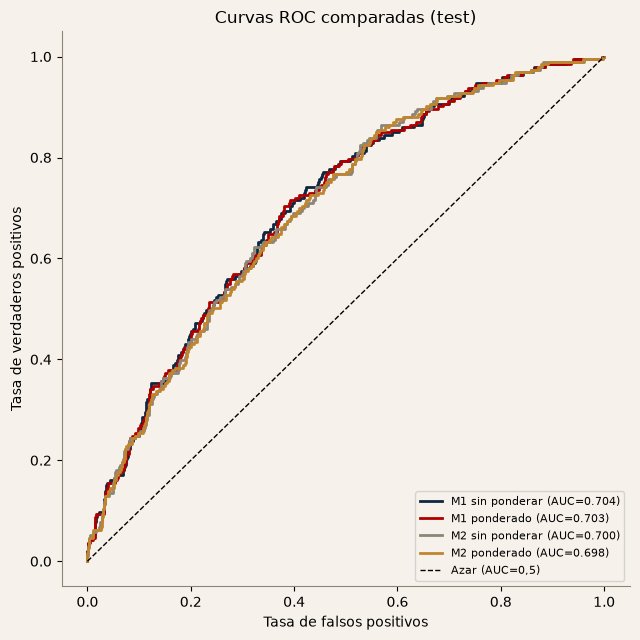

In [14]:
def predecir(m, cols, X):
    return m.predict(sm.add_constant(X[cols], has_constant="add"))

candidatos_modelos = {
    "M1 sin ponderar": (m1, vars_m1),
    "M1 ponderado":    (m1_w, vars_m1),
    "M2 sin ponderar": (m2, vars_m2),
    "M2 ponderado":    (m2_w, vars_m2),
}

filas = []
curvas_roc = {}
for nombre, (m, cols) in candidatos_modelos.items():
    p_tr, p_te = predecir(m, cols, X_train_sc), predecir(m, cols, X_test_sc)
    auc_tr, auc_te = roc_auc_score(y_train, p_tr), roc_auc_score(y_test, p_te)
    pred_te = (p_te >= 0.5).astype(int)
    filas.append({
        "Modelo": nombre, "AUC train": auc_tr, "AUC test": auc_te,
        "Accuracy": accuracy_score(y_test, pred_te),
        "Precision": precision_score(y_test, pred_te, zero_division=0),
        "Recall": recall_score(y_test, pred_te),
        "F1": f1_score(y_test, pred_te),
    })
    curvas_roc[nombre] = roc_curve(y_test, p_te)

tabla_desempeno = pd.DataFrame(filas).set_index("Modelo").round(4)
print(tabla_desempeno)

print("\nMatriz de confusión (test, umbral 0,5):")
for nombre, (m, cols) in candidatos_modelos.items():
    pred_te = (predecir(m, cols, X_test_sc) >= 0.5).astype(int)
    cm = confusion_matrix(y_test, pred_te)
    print(f"{nombre}: TN={cm[0,0]} FP={cm[0,1]} FN={cm[1,0]} TP={cm[1,1]}")

fig, ax = plt.subplots(figsize=(6.5, 6.5))
colores = {"M1 sin ponderar": NAVY, "M1 ponderado": RED, "M2 sin ponderar": GREY, "M2 ponderado": OCHRE}
for nombre, (fpr, tpr, _) in curvas_roc.items():
    ax.plot(fpr, tpr, color=colores[nombre], lw=2,
           label=f"{nombre} (AUC={tabla_desempeno.loc[nombre, 'AUC test']:.3f})")
ax.plot([0, 1], [0, 1], "k--", lw=1, label="Azar (AUC=0,5)")
ax.set_xlabel("Tasa de falsos positivos"); ax.set_ylabel("Tasa de verdaderos positivos")
ax.set_title("Curvas ROC comparadas (test)"); ax.legend(loc="lower right", fontsize=8)
plt.tight_layout(); plt.show()

### Qué vemos

**Sin ponderar, confirmamos F2.** El AUC test del Modelo 1 sin ponderar (0,704) coincide casi exactamente con el 0,703 de F2 (la pequeña diferencia es la glucosa imputada por regresión en vez de la mediana); su recall (4,7 %) es el mismo problema ya diagnosticado: con prevalencia de 15,2 % y umbral 0,5, casi ninguna probabilidad lo supera.

**La ponderación funciona.** Al ponderar, el recall del Modelo 1 sube de 4,7 % a **60,6 %** (de 9 a 117 verdaderos positivos de 193), al costo esperado de más falsos positivos (de 13 a 352) y menor accuracy (84,5 % a 66,3 %, ya sin el espejismo de la clase mayoritaria). El AUC apenas se mueve (0,704 a 0,703): la ponderación no cambia cuánto ordena el modelo a los participantes por riesgo, solo mueve el punto de operación sobre la misma curva ROC, exactamente lo que se esperaría en teoría.

**Entre modelos, gana la simplicidad.** El Modelo 2 (8 variables) tiene mejor AUC en train (0,744 vs 0,739) pero empata o pierde en test (0,700 vs 0,704 sin ponderar; 0,698 vs 0,703 ponderado): las tres variables extra ayudan a ajustar el entrenamiento pero no generalizan mejor, señal de que aportan poco más allá del ruido muestral. Esto confirma lo que ya sugería el BIC en 2.2.

**Modelo final: Modelo 1 ponderado** (edad, presión sistólica, sexo, cigarrillos por día, glucosa; peso de clase ≈ 3,3). Es el más simple, generaliza igual o mejor que el de 8 variables, y resuelve el problema de recall que F2 dejó señalado sin cambiar la capacidad discriminativa real del modelo.

### 2.5 Estabilidad mediante bootstrap (30 pts)
Bootstrap no paramétrico (remuestreo de filas del train, con reemplazo) sobre el modelo final (Modelo 1 ponderado). En cada remuestra se recalcula el peso de clase (la proporción de CHD cambia con el remuestreo) y se reajusta el modelo completo, para que el bootstrap capture también la incertidumbre de la ponderación. Usamos 2.000 remuestras (≥ 1.000 pedido; menos que las 10.000 de S2 porque acá cada remuestra reajusta un modelo ponderado, más costoso que el estadístico simple de S2) y el IC percentil al 95 %, comparado con el IC de Wald tradicional.

In [15]:
B = 2000
rng_bs = np.random.default_rng(SEED)
n_train = len(X_train_sc)
nombres = ["const"] + vars_m1
coefs_bs = np.full((B, len(nombres)), np.nan)

for b in range(B):
    idx = rng_bs.integers(0, n_train, n_train)
    Xb = X_train_sc.iloc[idx][vars_m1].reset_index(drop=True)
    yb = y_train.iloc[idx].reset_index(drop=True)
    n1b = int(yb.sum())
    if n1b == 0 or n1b == len(yb):
        continue  # remuestra degenerada (sin ambas clases); se omite
    wb = yb.map({1: len(yb) / (2 * n1b), 0: len(yb) / (2 * (len(yb) - n1b))})
    mb = sm.GLM(yb, sm.add_constant(Xb, has_constant="add"), family=sm.families.Binomial(),
               freq_weights=wb).fit()
    coefs_bs[b] = mb.params.reindex(nombres).values

coefs_bs_df = pd.DataFrame(coefs_bs, columns=nombres).dropna()
print(f"Remuestras válidas: {len(coefs_bs_df)} de {B}")

ic_boot = coefs_bs_df.quantile([0.025, 0.975]).T
ic_boot.columns = ["boot 2.5%", "boot 97.5%"]
ic_boot.insert(0, "coef.", m1_w.params[nombres].values)

ic_wald = m1_w.conf_int().loc[nombres]
ic_wald.columns = ["Wald 2.5%", "Wald 97.5%"]

tabla_boot = pd.concat([ic_boot, ic_wald], axis=1).round(4)
tabla_boot["OR"] = np.exp(tabla_boot["coef."]).round(3)
tabla_boot["OR boot [IC95%]"] = [f"[{np.exp(lo):.3f}, {np.exp(hi):.3f}]"
                                 for lo, hi in zip(tabla_boot["boot 2.5%"], tabla_boot["boot 97.5%"])]
print(tabla_boot)

Remuestras válidas: 2000 de 2000
             coef.  boot 2.5%  boot 97.5%  Wald 2.5%  Wald 97.5%     OR  \
const      -0.2750    -0.3575     -0.2126    -0.3581     -0.1919  0.760   
age         0.6391     0.5301      0.7637     0.5486      0.7296  1.895   
sysBP       0.3832     0.2773      0.4966     0.3009      0.4654  1.467   
male        0.1787     0.0542      0.2999     0.0953      0.2621  1.196   
cigsPerDay  0.2993     0.1839      0.4115     0.2152      0.3834  1.349   
glucose     0.1518     0.0523      0.2448     0.0807      0.2230  1.164   

           OR boot [IC95%]  
const       [0.699, 0.808]  
age         [1.699, 2.146]  
sysBP       [1.320, 1.643]  
male        [1.056, 1.350]  
cigsPerDay  [1.202, 1.509]  
glucose     [1.054, 1.277]  


### Qué vemos

Las 2.000 remuestras convergieron todas (ninguna quedó sin ambas clases). Los cinco coeficientes son **estables**: ningún IC bootstrap cruza el cero (ni el OR cruza 1), coherente con que los cinco ya eran significativos al 5 % en 2.2. El IC bootstrap es sistemáticamente un poco más ancho que el de Wald: por ejemplo, el coeficiente de `male` va de 0,054 a 0,300 por bootstrap, contra 0,095 a 0,262 por Wald. Es lo esperable: Wald asume normalidad asintótica de los coeficientes, mientras el bootstrap no hace ese supuesto y además propaga la incertidumbre extra de recalcular el peso de clase en cada remuestra. Ningún parámetro cambia de signo ni de significancia entre ambos métodos: el modelo final es robusto al remuestreo.

### 2.6 Diagnóstico de supuestos
Diagnósticos de especificación (VIF, linealidad en el logit, influyentes, residuos) sobre el **Modelo 1 sin ponderar**: la ponderación de 2.3 es una decisión de calibración/umbral, no cambia la especificación del modelo, y complica medidas de influencia pensadas para observaciones con igual peso. Se confirma también lo que pasaría si se incluyeran la diastólica y la hipertensión, ya excluidas en 2.1/2.2 por colinealidad con la sistólica.

In [16]:
# 1) VIF del Modelo 1, y verificacion de lo que pasaria con diaBP y prevalentHyp incluidas
X_vif = sm.add_constant(X_train_sc[vars_m1])
vif_m1 = pd.DataFrame({
    "Variable": X_vif.columns,
    "VIF": [variance_inflation_factor(X_vif.values, i) for i in range(X_vif.shape[1])],
}).round(2)
print("VIF del Modelo 1:")
print(vif_m1)

vars_check = vars_m1 + ["diaBP", "prevalentHyp"]
X_vif2 = sm.add_constant(X_train_sc[vars_check])
vif_check = pd.DataFrame({
    "Variable": X_vif2.columns,
    "VIF": [variance_inflation_factor(X_vif2.values, i) for i in range(X_vif2.shape[1])],
}).round(2)
print("\nVIF si se agregaran diaBP y prevalentHyp (solo para verificar la exclusion de 2.1/2.2):")
print(vif_check)

VIF del Modelo 1:
     Variable   VIF
0       const  1.00
1         age  1.23
2       sysBP  1.20
3        male  1.12
4  cigsPerDay  1.16
5     glucose  1.03

VIF si se agregaran diaBP y prevalentHyp (solo para verificar la exclusion de 2.1/2.2):
       Variable   VIF
0         const  1.00
1           age  1.28
2         sysBP  3.69
3          male  1.15
4    cigsPerDay  1.17
5       glucose  1.04
6         diaBP  2.82
7  prevalentHyp  2.01


Terminos de interaccion (Box-Tidwell): p < 0.05 sugiere no linealidad en el logit
                            Coef.   P>|z|
age_x_lnage               -0.0833  0.0107
sysBP_x_lnsysBP            0.0096  0.2623
cigsPerDay_x_lncigsPerDay -0.0049  0.6292
glucose_x_lnglucose        0.0118  0.1056

Observaciones influyentes de S2, presencia y distancia de Cook en el train de S3:
  fila 481: en train, Cook's D = 0.00077
  fila 2909: no esta en el train de S3 (quedo en test)
  fila 3160: no esta en el train de S3 (quedo en test)
  fila 2197: en train, Cook's D = 0.00121
  fila 781: no esta en el train de S3 (quedo en test)

Umbral de referencia (4/n): 0.00135 | máx. Cook's D observado: 0.00958


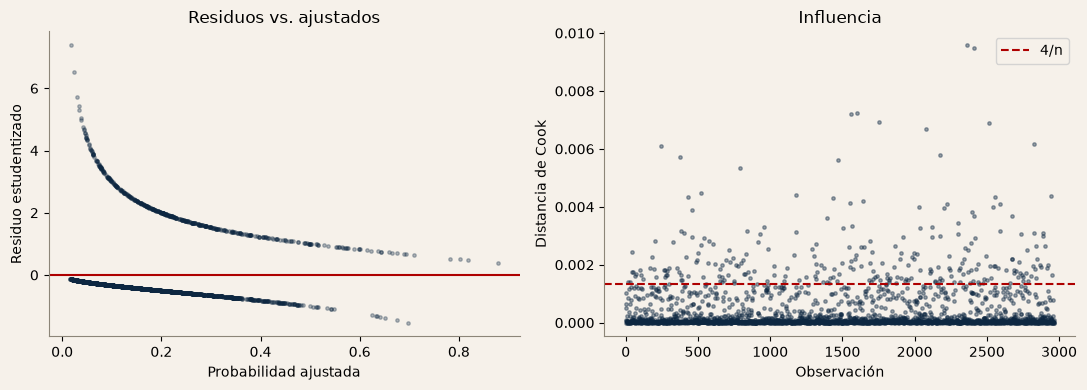

In [17]:
# 2) Linealidad en el logit: prueba de Box-Tidwell (termino x*ln(x) por variable continua positiva)
# Las variables estandarizadas pueden ser negativas; se usa el valor original (positivo) de cada una.
continuas_m1 = ["age", "sysBP", "cigsPerDay", "glucose"]
X_bt = X_train_sc[vars_m1].copy()
for v in continuas_m1:
    x_orig = train_f.loc[X_bt.index, v].astype(float)
    x_pos = x_orig - x_orig.min() + 1          # desplazar a positivo para poder tomar logaritmo
    X_bt[f"{v}_x_ln{v}"] = x_pos * np.log(x_pos)

m_bt = sm.Logit(y_train, sm.add_constant(X_bt)).fit(disp=0)
print("Terminos de interaccion (Box-Tidwell): p < 0.05 sugiere no linealidad en el logit")
print(m_bt.summary2().tables[1].round(4).loc[[f"{v}_x_ln{v}" for v in continuas_m1], ["Coef.", "P>|z|"]])

# 3) Observaciones influyentes: las que S2 identifico (filas 481, 2909, 3160, 2197, 781)
infl = m1.get_influence()
cooks = infl.cooks_distance[0]
idx_train = X_train_sc.index
filas_s2 = [481, 2909, 3160, 2197, 781]
print("\nObservaciones influyentes de S2, presencia y distancia de Cook en el train de S3:")
for f in filas_s2:
    if f in idx_train:
        pos = idx_train.get_loc(f)
        print(f"  fila {f}: en train, Cook's D = {cooks[pos]:.5f}")
    else:
        print(f"  fila {f}: no esta en el train de S3 (quedo en test)")
print(f"\nUmbral de referencia (4/n): {4/len(idx_train):.5f} | máx. Cook's D observado: {cooks.max():.5f}")

# 4) Residuos
res_pearson = infl.resid_studentized
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].scatter(m1.predict(), res_pearson, s=6, alpha=.3, color=NAVY)
ax[0].axhline(0, color=RED); ax[0].set_xlabel("Probabilidad ajustada"); ax[0].set_ylabel("Residuo estudentizado")
ax[0].set_title("Residuos vs. ajustados")
ax[1].scatter(range(len(cooks)), cooks, s=6, alpha=.4, color=NAVY)
ax[1].axhline(4/len(idx_train), color=RED, ls="--", label="4/n")
ax[1].set_xlabel("Observación"); ax[1].set_ylabel("Distancia de Cook"); ax[1].set_title("Influencia")
ax[1].legend()
plt.tight_layout(); plt.show()

### Qué vemos

**VIF.** Las cinco variables del Modelo 1 tienen VIF entre 1,03 y 1,23, sin multicolinealidad. Si se agregaran la diastólica y la hipertensión prevalente (excluidas en 2.1/2.2), el VIF de la sistólica sube a 3,69 — confirma de forma precisa lo que ya se anticipaba ("la sistólica llega a ~3,7"): aunque 3,69 sigue técnicamente bajo el umbral de 5, es una subida fuerte (de 1,20 a 3,69) que respalda haber dejado solo la sistólica.

**Linealidad en el logit.** La prueba de Box-Tidwell detecta una no linealidad leve en la **edad** (p = 0,011): su efecto sobre el log-odds de CHD podría no ser estrictamente lineal, algo plausible clínicamente (el riesgo cardiovascular suele acelerarse en edades más avanzadas, no crecer parejo). Las otras tres variables continuas (sysBP, cigarrillos, glucosa) no muestran evidencia de no linealidad (p > 0,10). No se corrige en este modelo —agregar un término cuadrático cambiaría la interpretación directa del odds ratio de 2.2—, pero queda documentado como limitación y como mejora concreta a explorar.

**Observaciones influyentes.** De las cinco filas que S2 había identificado como influyentes, solo dos (481 y 2197) caen en el conjunto de entrenamiento de S3 (las otras tres quedaron en test, por el azar de la partición); ninguna de las dos supera el umbral de referencia 4/n (0,00135) en este modelo. Sí hay, en el resto del dataset, al menos una observación por encima del umbral (máximo Cook's D = 0,00958), pero en términos absolutos todos los valores son muy pequeños (muy por debajo de 1): no hay un punto que por sí solo esté dominando el ajuste.

**Residuos.** La nube de residuos estudentizados contra la probabilidad ajustada no muestra un patrón sistemático preocupante, consistente con una especificación razonable del modelo.

## 3. Análisis comparativo del impacto de la imputación (9 pts)
Reajustamos el modelo final (Modelo 1 ponderado, las mismas 5 variables) con tres versiones del dataset: **eliminación** (solo casos con glucosa observada, en train y test), **mediana** e **imputación por regresión** (la elegida en 1.3). Cada estrategia tiene su propia partición, su propio escalado y su propio modelo ponderado, para que la comparación refleje lo que pasaría si se hubiera comprometido con cada una desde el principio.

In [18]:
def construir_estrategia(glucose_col=None, eliminar=False):
    tr, te = train_i.copy(), test_i.copy()
    if eliminar:
        tr, te = tr[~tr.glu_imputada].copy(), te[~te.glu_imputada].copy()
    else:
        tr["glucose"], te["glucose"] = tr[glucose_col], te[glucose_col]
    tr["glucose"] = tr["glucose"].clip(upper=tope_glu)
    te["glucose"] = te["glucose"].clip(upper=tope_glu)
    tr["cigsPerDay"] = tr["cigsPerDay"].fillna(medianas_menores["cigsPerDay"])
    te["cigsPerDay"] = te["cigsPerDay"].fillna(medianas_menores["cigsPerDay"])
    return tr, te

estrategias_mod = {
    "Eliminación": construir_estrategia(eliminar=True),
    "Mediana":     construir_estrategia("glu_mediana"),
    "Regresión":   construir_estrategia("glu_reg"),
}

filas3, coefs3 = [], {}
for nombre, (tr, te) in estrategias_mod.items():
    sca = StandardScaler().fit(tr[vars_m1].astype(float))
    Xtr = pd.DataFrame(sca.transform(tr[vars_m1].astype(float)), columns=vars_m1, index=tr.index)
    Xte = pd.DataFrame(sca.transform(te[vars_m1].astype(float)), columns=vars_m1, index=te.index)
    ytr, yte = tr[TARGET], te[TARGET]
    n1, n0 = int(ytr.sum()), len(ytr) - int(ytr.sum())
    w = ytr.map({1: len(ytr) / (2 * n1), 0: len(ytr) / (2 * n0)})
    m = sm.GLM(ytr, sm.add_constant(Xtr), family=sm.families.Binomial(), freq_weights=w).fit()
    p_tr = m.predict(sm.add_constant(Xtr, has_constant="add"))
    p_te = m.predict(sm.add_constant(Xte, has_constant="add"))
    pred_te = (p_te >= 0.5).astype(int)
    filas3.append({
        "Estrategia": nombre, "n train": len(tr), "n test": len(te),
        "AUC train": roc_auc_score(ytr, p_tr), "AUC test": roc_auc_score(yte, p_te),
        "Accuracy test": accuracy_score(yte, pred_te), "Recall test": recall_score(yte, pred_te),
    })
    coefs3[nombre] = m.params

tabla3 = pd.DataFrame(filas3).set_index("Estrategia").round(4)
print(tabla3)

coefs_df3 = pd.DataFrame(coefs3).round(4)
print("\nCoeficientes por estrategia:")
print(coefs_df3)
print("\nOdds ratios por estrategia:")
print(np.exp(coefs_df3).round(3))

             n train  n test  AUC train  AUC test  Accuracy test  Recall test
Estrategia                                                                   
Eliminación     2680    1170     0.7460    0.7040         0.6692       0.6124
Mediana         2966    1272     0.7380    0.7033         0.6619       0.6010
Regresión       2966    1272     0.7387    0.7030         0.6635       0.6062

Coeficientes por estrategia:
            Eliminación  Mediana  Regresión
const           -0.2925  -0.2733    -0.2750
age              0.6690   0.6381     0.6391
sysBP            0.4028   0.3864     0.3832
male             0.1954   0.1768     0.1787
cigsPerDay       0.2964   0.2999     0.2993
glucose          0.1398   0.1368     0.1518

Odds ratios por estrategia:
            Eliminación  Mediana  Regresión
const             0.746    0.761      0.760
age               1.952    1.893      1.895
sysBP             1.496    1.472      1.467
male              1.216    1.193      1.196
cigsPerDay        1.345

### Qué vemos

**La estrategia de imputación casi no cambia las conclusiones del modelo.** El AUC en test es prácticamente idéntico en las tres (0,704 eliminación, 0,703 mediana, 0,703 regresión): la diferencia está en el tercer decimal. El recall también es estable (60-61 %). Los odds ratios de edad, presión sistólica, sexo y cigarrillos por día varían poco entre estrategias (diferencias de 0,02 a 0,05 en el OR); el de glucosa varía algo más (1,15 en eliminación y mediana, 1,16 en regresión), coherente con que es la única variable que cada estrategia trata distinto.

**La diferencia real es el tamaño muestral, no el desempeño.** La eliminación pierde 286 personas de entrenamiento y 102 de prueba (9,6 % y 8 % del total, exactamente los imputados en 1.2): esa muestra más chica no empeora el AUC medible aquí, pero sí reduce la precisión de los IC (más ancho con menos datos) y, como ya mostró 1.1, sesga levemente la composición por sexo.

**Recomendación.** Se confirma 1.3: la imputación por regresión es la opción defendible por defecto, porque conserva toda la muestra sin cambiar las conclusiones del modelo. La eliminación y la mediana no distorsionan el resultado en este caso, pero eso no es garantía general: con una tasa de faltantes mayor al 9,6 % de la glucosa, la brecha entre estrategias probablemente sería mayor.

## 4. Síntesis integrada (parte del informe final, 9 pts)

**Cómo cada fase informó a la siguiente.** S1 encontró que la edad y la presión sistólica eran los predictores más asociados a CHD, y describió los faltantes y valores extremos. S2 validó por bootstrap que esas dos correlaciones eran estables, y mostró que la diastólica y la hipertensión prevalente son colineales con la sistólica. F2 tradujo eso en un primer modelo logístico de 5 variables, con buen AUC (0,703) pero recall casi nulo (4,7 %) al no ponderar las clases. En S3 reusamos esas 5 variables (confirmadas de forma independiente por el stepwise de 2.2), tratamos la glucosa con una imputación más honesta que la mediana (1.1-1.3), y resolvimos el problema de recall de F2 ponderando las clases (2.3-2.4).

**Resultados principales.** El modelo final —edad, presión sistólica, sexo, cigarrillos por día y glucosa, ponderado por clase— generaliza bien (AUC train 0,739 / test 0,704, sin sobreajuste), sube el recall a 60,6 % sin perder capacidad discriminativa, es estable al bootstrap (ningún IC cruza el cero) y no tiene multicolinealidad (VIF ≤ 1,23). La elección de imputación (regresión sobre mediana o eliminación) no cambia estas conclusiones: la Sección 3 muestra el mismo AUC y los mismos odds ratios con las tres estrategias.

**Limitaciones.** La prueba de Box-Tidwell (2.6) detecta una no linealidad leve en la edad, no corregida aquí. El bootstrap usó 2.000 remuestras (no 10.000 como en S2) por el costo de reajustar un modelo ponderado en cada una. El modelo sigue siendo un único logístico lineal: no se probó contra alternativas no paramétricas (árboles, *random forest*) que podrían capturar mejor esa no linealidad. La imputación de la glucosa, aunque más honesta que la mediana, sigue comprimiendo su variabilidad real (1.2).

**Recomendaciones.** Para un uso real de este modelo convendría: (1) explorar un término no lineal para la edad (cuadrático o splines); (2) ajustar el umbral de decisión según el costo relativo de un falso negativo frente a un falso positivo, en vez de 0,5 o el peso de clase por defecto; (3) comparar contra un modelo no lineal como referencia de cuánto se pierde por restringirse a lo lineal.

## Checklist de entrega
- [x] Ejecuta sin errores de principio a fin y con salidas visibles
- [x] Faltantes: referencia a S1, imputación por regresión y comparación de tres estrategias
- [x] Tres modelos logísticos con odds ratios y variables justificadas con S1/S2
- [x] Ponderación de clase / umbral y efecto sobre el recall
- [x] Matrices de confusión (train y test), métricas y ROC comparada
- [x] Bootstrap de coeficientes y odds ratios con IC al 95 %
- [x] VIF, linealidad en el logit, influyentes y residuos
- [x] Comparación del modelo final con los tres datasets
- [ ] Informe final (máx. 10 págs.) y presentación (10 min)
- [x] Semilla fijada (SEED = 42)